In [33]:
#1.Import Libraries
import pandas as pd
import numpy as np

In [34]:
#2.Data load
df=pd.read_csv("UCI_Credit_Card.csv")

In [35]:
# Columns ke naam simple karo
df.rename(columns={"PAY_0": "PAY_1","default.payment.next.month":"DEFAULT"},inplace=True)
df.drop("ID",axis=1,inplace=True)

In [36]:
# Quick check
print(df.shape)  #rows/columns batata hai--> 30000,24
print(df.isnull().sum().sum())   #missing values ka sum
print(df["DEFAULT"].value_counts(normalize=True))   #-22% default

(30000, 24)
0
DEFAULT
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [37]:
#3.Data Cleaning (galat category fix)
df['EDUCATION']=df['EDUCATION'].replace({0:4,5:4,6:4})
df['MARRIAGE']=df['MARRIAGE'].replace({0:3})

In [38]:
#4.Feature engineering (new columns)
pay_cols=[f"PAY_{i}" for i in range(1,7)]
bill_cols=[f"BILL_AMT{i}" for i in range(1,7)]
payment_cols=[f"PAY_AMT{i}" for i in range(1,7)]

In [39]:
df['AVG_DELAY']=df[pay_cols].mean(axis=1)
df['MAX_DELAY']=df[pay_cols].max(axis=1)
df['UTILIZATION']=df[bill_cols].mean(axis=1)/df['LIMIT_BAL']
df["PAY_RATIO"]=df[payment_cols].sum(axis=1)/df[bill_cols].sum(axis=1).clip(lower=1)

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

In [41]:
# Feature (X) and target (Y)
x=df.drop("DEFAULT",axis=1)
y=df["DEFAULT"]

In [42]:
#5.Train-Test Split (stratify= dono mein default % same rahe)
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2, stratify=y, random_state=42)

In [43]:
#5.Scaling (sirf Logistic Regression ke liye)
scaler=StandardScaler()
x_train_sc=scaler.fit_transform(x_train)
x_test_sc=scaler.transform(x_test)

In [44]:
#6.Model 1: Logistic Regression
#class_weight="balanced"=imbalance handle karta hai
lr=LogisticRegression(class_weight="balanced",max_iter=1000)
lr.fit(x_train_sc, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [45]:
lr_pred=lr.predict(x_test_sc)
lr_prob=lr.predict_proba(x_test_sc)[:,1]

In [46]:
print(classification_report(y_test, lr_pred))
print("ROC_AUC:", roc_auc_score(y_test, lr_prob))

              precision    recall  f1-score   support

           0       0.88      0.75      0.81      4673
           1       0.41      0.63      0.50      1327

    accuracy                           0.72      6000
   macro avg       0.64      0.69      0.65      6000
weighted avg       0.77      0.72      0.74      6000

ROC_AUC: 0.7251490911811846


In [47]:
#7.Model 2: Random Forest
rf=RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=1)

In [48]:
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

In [49]:
rf_pred=rf.predict(x_test)
rf_prob=rf.predict_proba(x_test)[:,1]

In [50]:
print(classification_report(y_test, rf_pred))
print("ROC-AUC:",roc_auc_score(y_test, rf_prob))

              precision    recall  f1-score   support

           0       0.86      0.88      0.87      4673
           1       0.54      0.48      0.51      1327

    accuracy                           0.80      6000
   macro avg       0.70      0.68      0.69      6000
weighted avg       0.79      0.80      0.79      6000

ROC-AUC: 0.7606910161164095


#8.Threshold tuning
# At the default threshold of 0.5, Recall was only 49%. Lowering the threshold allows us to capture more defaulters.

In [51]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [52]:
for t in [0.5,0.4,0.35,0.3,0.25]:
    pred=(rf_prob>=t).astype(int)
    print(t,
         "Prediction:",round(precision_score(y_test,pred),2),
         "Recall:",round(recall_score(y_test,pred),2),
         "F1:",round(f1_score(y_test, pred),2))

0.5 Prediction: 0.54 Recall: 0.49 F1: 0.51
0.4 Prediction: 0.48 Recall: 0.59 F1: 0.53
0.35 Prediction: 0.43 Recall: 0.64 F1: 0.51
0.3 Prediction: 0.38 Recall: 0.7 F1: 0.49
0.25 Prediction: 0.34 Recall: 0.78 F1: 0.47


In [53]:
#9.Model 3: Gradient Boosting
from sklearn.ensemble import HistGradientBoostingClassifier

In [54]:
gb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                    max_depth=4, class_weight="balanced",
                                    random_state=42)
gb.fit(x_train, y_train)

gb_pred = gb.predict(x_test)
gb_prob = gb.predict_proba(x_test)[:, 1]

In [55]:
print(classification_report(y_test, gb_pred))
print("ROC-AUC:", roc_auc_score(y_test, gb_prob))

              precision    recall  f1-score   support

           0       0.88      0.79      0.84      4673
           1       0.46      0.63      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.67      0.71      0.68      6000
weighted avg       0.79      0.76      0.77      6000

ROC-AUC: 0.7792840946346205


In [56]:
#10.Model Compariron
models={"Logistic Regression":(lr_pred, lr_prob),
       "Random Forest": (rf_pred, rf_prob),
        "Gradient Boosting": (gb_pred, gb_prob)}

In [57]:
rows = []
for name, (pred, prob) in models.items():
    rows.append({"Model": name,
                 "Accuracy": round((pred == y_test).mean(), 2),
                 "Precision": round(precision_score(y_test, pred), 2),
                 "Recall": round(recall_score(y_test, pred), 2),
                 "F1": round(f1_score(y_test, pred), 2),
                 "ROC-AUC": round(roc_auc_score(y_test, prob), 3)})

In [58]:
comparison = pd.DataFrame(rows)
comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.72,0.41,0.63,0.50,0.725
1,Random Forest,0.80,0.54,0.48,0.51,0.761
2,Gradient Boosting,0.76,0.46,0.63,0.53,0.779


In [59]:
#11.Feature importance
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

In [60]:
result = permutation_importance(gb, x_test, y_test, scoring="roc_auc",
                                n_repeats=5, random_state=42, n_jobs=-1)

In [61]:
imp = pd.Series(result.importances_mean, index=x_test.columns)
imp = imp.sort_values(ascending=False).head(10)

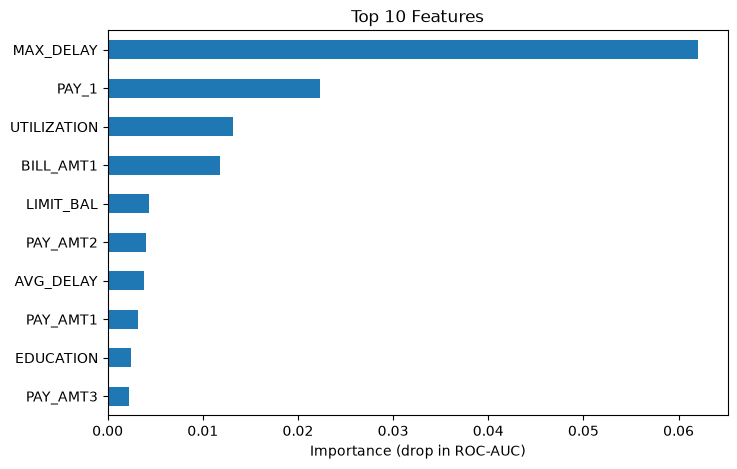

In [62]:
imp[::-1].plot(kind="barh", figsize=(8, 5), title="Top 10 Features")
plt.xlabel("Importance (drop in ROC-AUC)")
plt.show()

In [63]:
#12.Risk Segmentation (Low / Medium / High)
risk = x_test.copy()
risk["DEFAULT_PROB"] = gb_prob
risk["ACTUAL"] = y_test.values
risk["RISK_LEVEL"] = pd.cut(risk["DEFAULT_PROB"], bins=[0, 0.3, 0.6, 1],
                            labels=["Low", "Medium", "High"])

In [64]:
summary = risk.groupby("RISK_LEVEL", observed=False).agg(
    customers=("ACTUAL", "count"),
    actual_default_rate=("ACTUAL", "mean")).round(2)
summary

,customers,actual_default_rate
RISK_LEVEL,,
Low,2114,0.08
Medium,2574,0.18
High,1312,0.54


#13.Conclusion
- Gradient Boosting is the best model (ROU-AUC 0.28, Recall 63%)
- MAX_DELAY is the strongest predictor of default.
- High-risk cutomers have a default rate of 54% vs 8% for Low-risk.
- The bank can send early reminders to high-risk customers